In [16]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix

In [18]:
data = pd.read_csv("train.csv")

In [19]:
print("First 5 rows:")
print(data.head())

First 5 rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN

In [20]:
print("\nDataset Information:")
print(data.info())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [21]:
print("\nMissing Values:")
print(data.isnull().sum())


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [22]:
# Step 4: Handle missing values
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

In [23]:
# Step 5: Select useful columns and encode categorical variables
data = data[["Survived", "Pclass", "Sex", "Age",
             "SibSp", "Parch", "Fare", "Embarked"]]

In [24]:
data = pd.get_dummies(
    data,
    columns=["Sex", "Embarked"],
    drop_first=True
)

In [25]:
# Step 6: Split features (X) and target (y)
X = data.drop("Survived", axis=1)
y = data["Survived"]

In [26]:
# Step 7: Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [27]:
# Step 8 and 9: Apply and train Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [28]:
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [29]:
# Step 10: Make predictions
y_pred = model.predict(X_test)

In [30]:
# Step 11: Evaluate the model
print("\n--- Model Evaluation ---")


--- Model Evaluation ---


In [31]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

Accuracy: 0.8212290502793296


In [32]:
print("Precision:",
      precision_score(y_test, y_pred))

Precision: 0.8


In [33]:
print("Recall:",
      recall_score(y_test, y_pred))

Recall: 0.7567567567567568


In [34]:
print("F1-Score:",
      f1_score(y_test, y_pred))

F1-Score: 0.7777777777777778


In [35]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[91 14]
 [18 56]]


In [36]:
# Step 12: Feature Importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

In [37]:
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

In [38]:
print("\n--- Feature Importance ---")
print(importance)


--- Feature Importance ---
      Feature  Importance
5    Sex_male    0.273316
4        Fare    0.272058
1         Age    0.252745
0      Pclass    0.078616
2       SibSp    0.052192
3       Parch    0.038490
7  Embarked_S    0.023095
6  Embarked_Q    0.009488


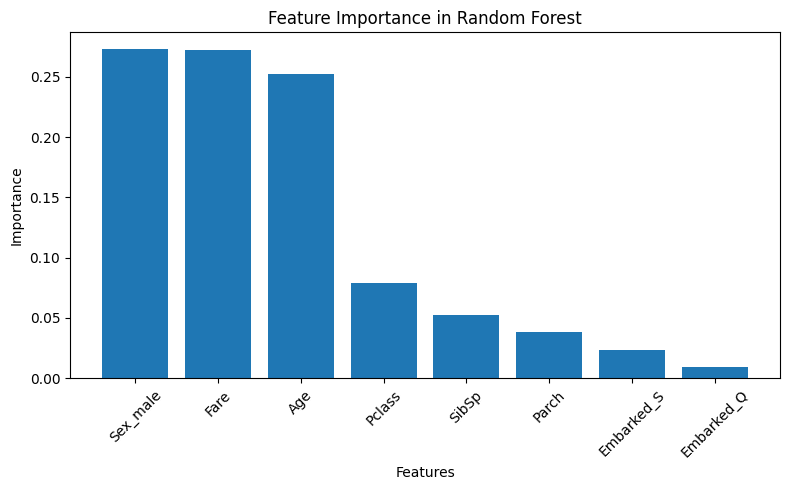

In [39]:
# Feature Importance Visualization
plt.figure(figsize=(8, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Random Forest")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
# Step 13: Conclusion
print("\nConclusion:")
print("The Random Forest model was successfully trained "
      "to predict Titanic passenger survival.")


Conclusion:
The Random Forest model was successfully trained to predict Titanic passenger survival.
